## Import libraries

In [34]:
import pandas as pd                  # Read and work with tabular data
import numpy as np                   # Numerical operations
import matplotlib.pyplot as plt      # Graphs and visualizations
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score,classification_report,ConfusionMatrixDisplay


print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df_test=pd.read_csv("datasets/test.csv", index_col=0)
df_train=pd.read_csv("datasets/train.csv", index_col=0)

In [38]:
#Display first five rows
df_train.head()


,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [43]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 24 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 103904 non-null  int64  
 1   Gender                             103904 non-null  str    
 2   Customer Type                      103904 non-null  str    
 3   Age                                103904 non-null  int64  
 4   Type of Travel                     103904 non-null  str    
 5   Class                              103904 non-null  str    
 6   Flight Distance                    103904 non-null  int64  
 7   Inflight wifi service              103904 non-null  int64  
 8   Departure/Arrival time convenient  103904 non-null  int64  
 9   Ease of Online booking             103904 non-null  int64  
 10  Gate location                      103904 non-null  int64  
 11  Food and drink                     103904 non-null

In [40]:
#Display number of rows and columns
print("Training Dataset shape:", df_train.shape)
print("Testing dataset shape:",df_test.shape)

Training Dataset shape: (103904, 24)
Testing dataset shape: (25976, 24)


In [42]:
#Display all column names
df_train.columns.tolist()

['id',
 'Gender',
 'Customer Type',
 'Age',
 'Type of Travel',
 'Class',
 'Flight Distance',
 'Inflight wifi service',
 'Departure/Arrival time convenient',
 'Ease of Online booking',
 'Gate location',
 'Food and drink',
 'Online boarding',
 'Seat comfort',
 'Inflight entertainment',
 'On-board service',
 'Leg room service',
 'Baggage handling',
 'Checkin service',
 'Inflight service',
 'Cleanliness',
 'Departure Delay in Minutes',
 'Arrival Delay in Minutes',
 'satisfaction']

In [44]:
#Remove unnecessary index columns if present
df_train = df_train.loc[:, ~df_train.columns.str.startswith("Unnamed")]
df_test = df_test.loc[:, ~df_train.columns.str.startswith("Unnamed")]

#Remove duplicate rows
df_train = df_train.drop_duplicates()
df_test=df_test.drop_duplicates()

print("Dataset cleaned successfully!")

Dataset cleaned successfully!


# Data visualization

In [45]:
df=pd.concat([df_train,df_test],ignore_index=True)
df.shape

(129880, 24)

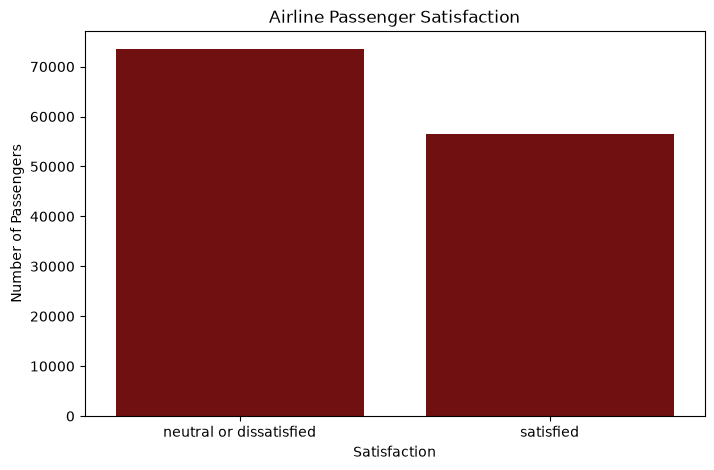

In [46]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="satisfaction",color="maroon")

plt.title("Airline Passenger Satisfaction")
plt.xlabel("Satisfaction")
plt.ylabel("Number of Passengers")

plt.show()


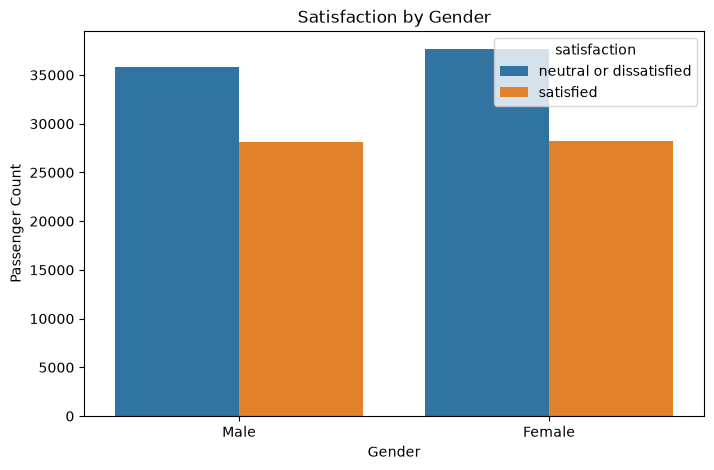

In [47]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Gender",
    hue="satisfaction"
)

plt.title("Satisfaction by Gender")
plt.xlabel("Gender")
plt.ylabel("Passenger Count")

plt.show()


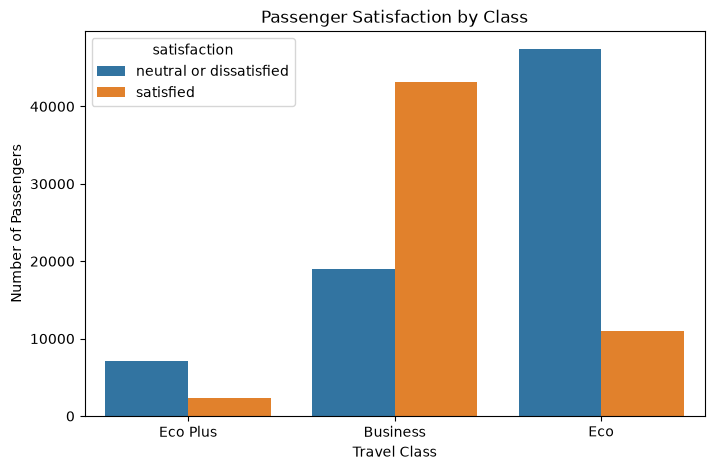

In [48]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Class",
    hue="satisfaction"
)

plt.title("Passenger Satisfaction by Class")
plt.xlabel("Travel Class")
plt.ylabel("Number of Passengers")

plt.show()


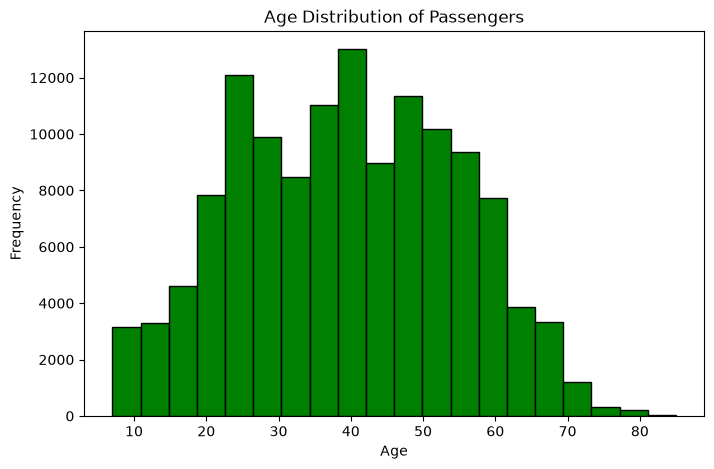

In [49]:

plt.figure(figsize=(8, 5))

plt.hist(df["Age"], bins=20, edgecolor="black",color="green")

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()


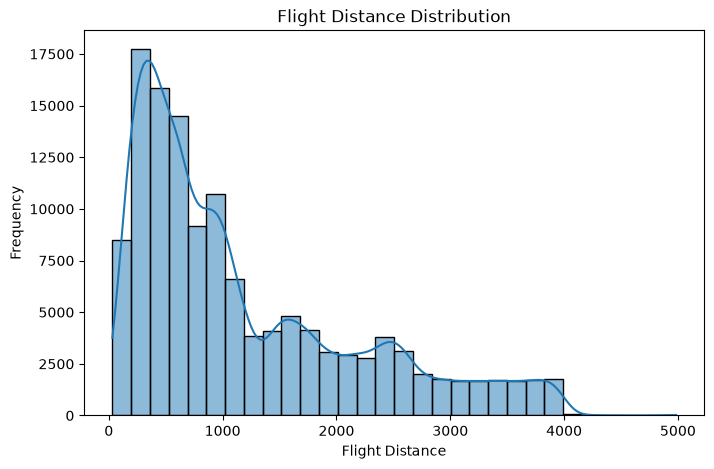

In [30]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Flight Distance",
    bins=30,
    kde=True
)

plt.title("Flight Distance Distribution")
plt.xlabel("Flight Distance")
plt.ylabel("Frequency")

plt.show()


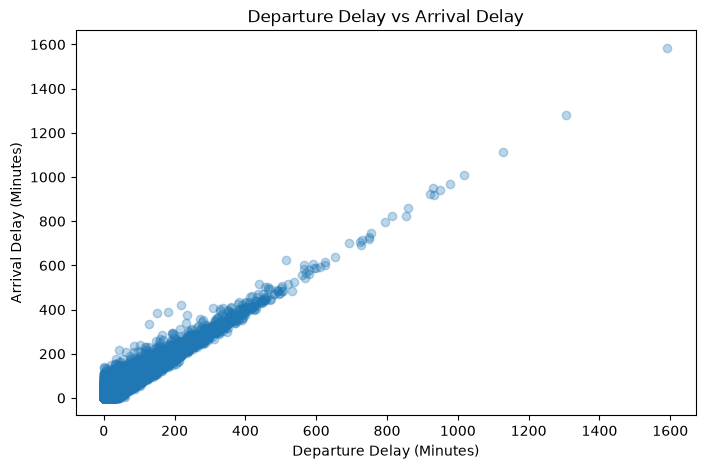

In [50]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Departure Delay in Minutes"],
    df["Arrival Delay in Minutes"],
    alpha=0.3
)

plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure Delay (Minutes)")
plt.ylabel("Arrival Delay (Minutes)")

plt.show()


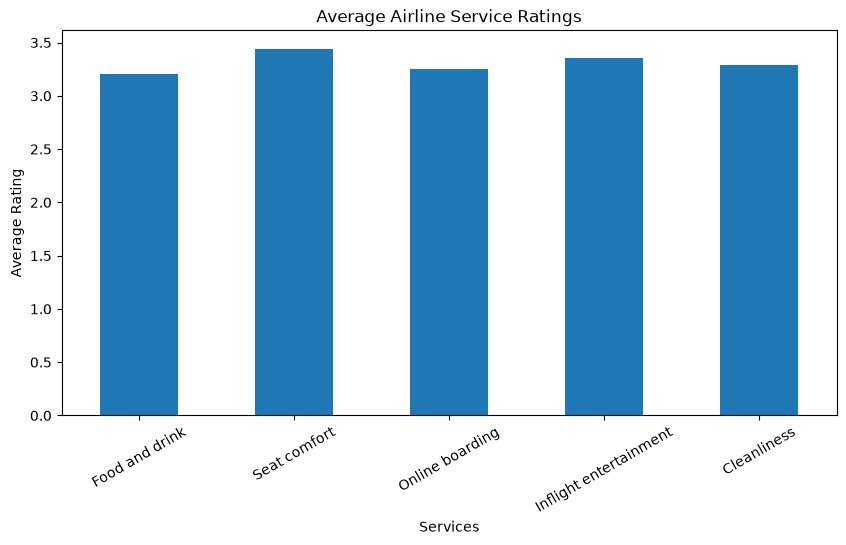

In [51]:

services = [
    "Food and drink",
    "Seat comfort",
    "Online boarding",
    "Inflight entertainment",
    "Cleanliness"
]

average_ratings = df[services].mean()

plt.figure(figsize=(10, 5))

average_ratings.plot(kind="bar")

plt.title("Average Airline Service Ratings")
plt.xlabel("Services")
plt.ylabel("Average Rating")
plt.xticks(rotation=30)

plt.show()


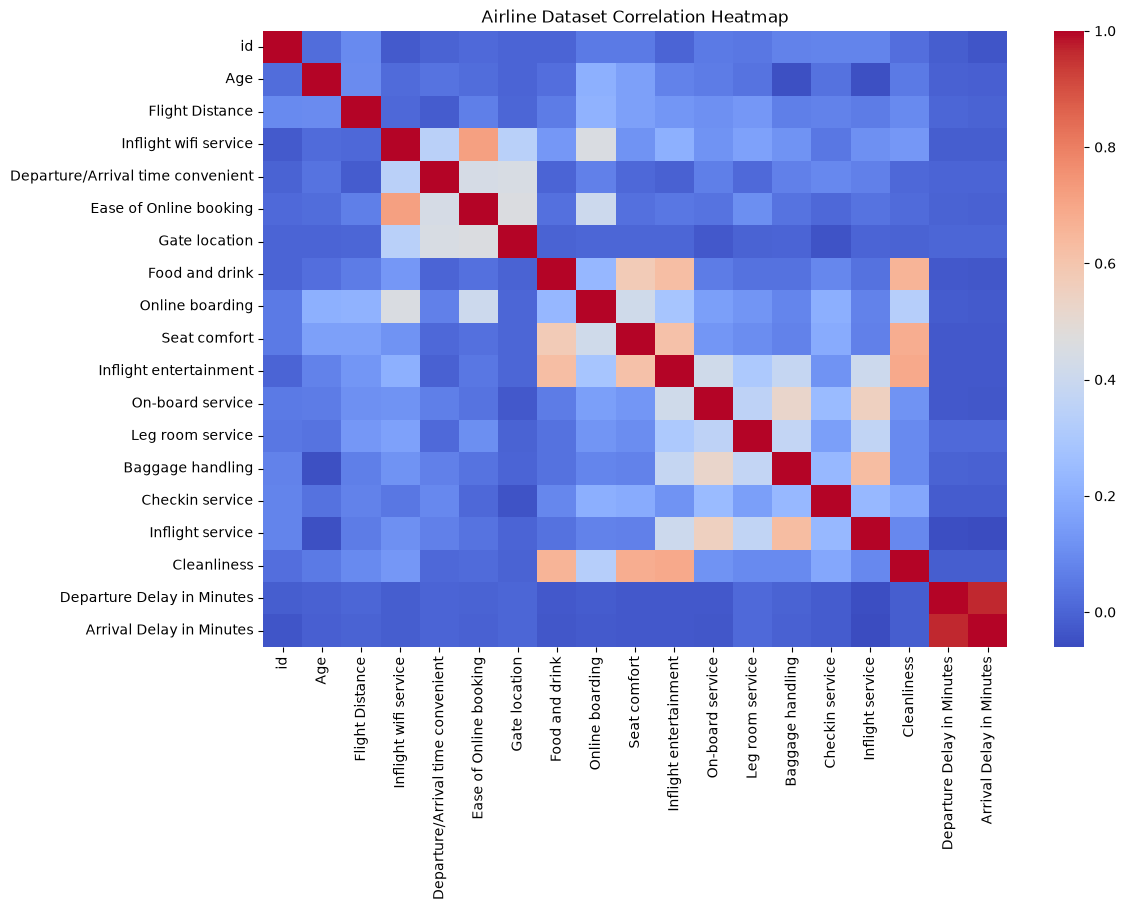

In [52]:

plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False
)

plt.title("Airline Dataset Correlation Heatmap")

plt.show()


In [53]:
print("Data has been visualized")

Data has been visualized
